# ICT-11 — Profils d'agence causale : à quelle échelle l'agence est-elle la plus lisible ?

**Série ICT** | Précédent : [ICT-33-SoupCollisions](./ICT-33-SoupCollisions-Python.ipynb) | Suivant : [ICT-13-AxelrodStrategicMorphodynamics](./ICT-13-AxelrodStrategicMorphodynamics-Python.ipynb) | [↑ Série ICT](README.md)

[← ICT-Series](README.md) | [↑ IIT](../README.md) | *Epic #4588, strate 3*

ICT-9 a défini l'**agence** d'un système de réaction-diffusion comme sa capacité à **réparer** une forme ablatée (un retour vers un point de consigne *intrinsèque*), mesurée *par contraste* avec un contrôle passif — la diffusion pure qui dissout. Toute cette mesure, cependant, était posée à une résolution unique : celle du pixel.

ICT-11 ouvre la **strate 3** en posant une question que l'émergence causale (Hoel) rend incontournable :

> **À quelle échelle spatiale l'agence est-elle la plus lisible ?** La réparation se lit-elle mieux au pixel près (micro), à l'échelle des tâches (méso), ou à celle de la texture globale (macro) ? Et cette échelle privilégiée — s'il y en a une — coïncide-t-elle avec celle où la dynamique est la *plus causalement déterminée* ?

La promesse de l'émergence causale (Hoel 2013, 2025 ; voir ICT-5/6) est qu'une macro-échelle peut concentrer **plus de pouvoir causal** que la micro — l'« information effective » maximisée par coarse-graining. Le présent notebook confronte cette intuition à une mesure **sans complaisance** : on ne déclare pas d'échelle privilégiée, on la **cherche**, et l'on accepte le verdict honnête « pas de granularité privilégiée détectée » si aucune courbe ne présente de pic méso.

## Les trois portes falsifiables (issue #4877)

Le notebook ne sera crédité d'aucun résultat s'il ne passe pas ces trois gates :

1. **Thèse réfutable (gate 1).** « L'agence est plus explicative à une échelle » n'est un résultat que si `repair_gain(échelle)`, `time_to_recover(échelle)` et `basin_return_probability(échelle)` produisent une **courbe non-monotone avec un pic identifiable** à une échelle méso. Courbes plates ou monotones → verdict honnête « pas de granularité privilégiée », **pas** un pic bricolé.
2. **Raccord Hoel non-décoratif (gate 2).** L'`effective_information` est calculée **aux mêmes échelles** que les mesures d'agence, et la corrélation EI(échelle) ↔ agence(échelle) est **explicitement testée**. Sans ce raccord chiffré, ICT-11 n'est qu'ICT-9 re-tracé à plusieurs zooms.
3. **Mêmes `do(.)` qu'ICT-9 (gate 3).** L'intervention `do(ablation)` est appliquée **pleine résolution**, **identiquement à chaque échelle** — seul le *zoom de mesure* change. Un contrôle qui varie avec l'échelle invalide la comparaison inter-échelles.

Le fil conducteur reste la **régime-dépendance** découverte au Cran A (ICT-10, `p̂`) : une capacité peut être réelle dans un régime et illusoire ailleurs. Ici, le « régime » est l'échelle d'observation.

> **Statut épistémique** — **hypothèse** : L'échelle méso-émergente est l'échelle privilégiée pour l'agence. Portée et détail dans la [matrice de dissociations](../../../docs/ict/dissociations-matrix.md).

In [1]:
import os, sys
import numpy as np
import matplotlib.pyplot as plt
sys.path.insert(0, os.getcwd())
from ict import reaction_diffusion as rd
from ict import agency as A
from ict import multiscale_agency as M
plt.rcParams["figure.dpi"] = 110
rng = np.random.default_rng(0)
print("ict modules charges (reaction_diffusion, agency, multiscale_agency)")

ict modules charges (reaction_diffusion, agency, multiscale_agency)


## 1. Le substrat et l'intervention `do(ablation)`

On reprend exactement le substrat d'ICT-9 : le système de **Gray-Scott** en régime **mitotique** (Pearson 1993 ; `F = 0.0367`, `k = 0.0649`), grille `96 × 96`. On laisse le motif se former depuis un germe central : un réseau de tâches auto-entretenu émerge, qui se divise et migre.

L'intervention est la même qu'en ICT-9 : on **ablate** un quadrant — `do(ablation)` au sens de Pearl, qui force la région à l'état nu (`U = 1`, `V = 0`, « pas de motif ici ») — puis on observe la trajectoire de récupération. Deux **mondes contrefactuels** issus de cette même intervention : l'un sous réaction-diffusion (le système *répare*), l'autre sous diffusion pure (le contrôle passif *dissout*).

**Gate 3 (rappel).** Cette ablation est faite **pleine résolution**, et elle est **identique à chaque échelle** testée ci-dessous. Ce qui change entre échelles n'est jamais l'intervention — c'est seulement le *zoom* auquel on mesure la récupération.

Motif forme : structure (variance de V) = 0.01234


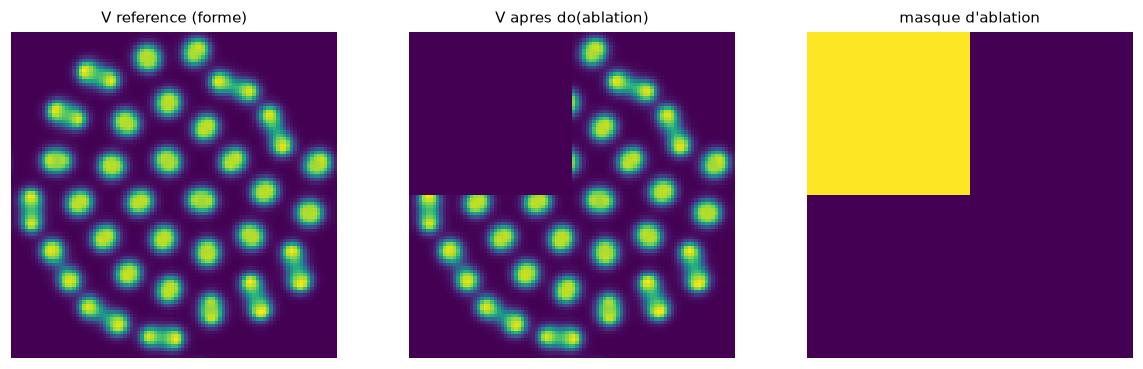

In [2]:
# Formation du motif mitotique (substrat ICT-9, grille 96x96)
model = rd.GrayScott()           # F=0.0367, k=0.0649 (regime mitotique de Pearson)
U_ref, V_ref = model.seed(n=96, block=12, noise=0.02, rng=np.random.default_rng(0))
U_ref, V_ref, _ = model.run(U_ref, V_ref, 6000)   # formation
S_ref = A.structure(V_ref)
print(f"Motif forme : structure (variance de V) = {S_ref:.5f}")

# do(ablation) : quadrant haut-gauche, pleine resolution
mask = A.quadrant_mask(96, quadrant=0)
U_abl, V_abl = A.ablate(U_ref, V_ref, mask)

fig, axes = plt.subplots(1, 3, figsize=(11, 3.4))
for ax, field, title in [(axes[0], V_ref, "V reference (forme)"),
                          (axes[1], V_abl, "V apres do(ablation)"),
                          (axes[2], mask.astype(float), "masque d'ablation")]:
    ax.imshow(field, cmap="viridis"); ax.set_title(title, fontsize=10); ax.axis("off")
plt.tight_layout(); plt.show()

## 2. Les échelles de mesure : le coarse-graining spatial

On définit l'échelle par la **taille de bloc** `b` du moyennage spatial : à l'échelle `b`, le champ `96 × 96` est réduit à `(96/b) × (96/b)` super-cellules, chacune égale à la moyenne des `b × b` pixels qu'elle couvre. C'est l'opération qu'un observateur à cette résolution ferait naturellement : il ne voit pas les pixels, il voit des tâches moyennées.

- **fin** (`b = 2`) : grille `48 × 48` = 2304 super-cellules — le champ quasi au niveau pixel ;
- **micro** (`b = 4`) : grille `24 × 24` = 576 super-cellules — les tâches individuelles sont résolues ;
- **méso** (`b = 8`) : grille `12 × 12` = 144 super-cellules — la structure des tâches commence à se moyenner ;
- **méso large** (`b = 16`) : grille `6 × 6` = 36 super-cellules — seules les grandes régions restent ;
- **macro** (`b = 32`) : grille `3 × 3` = 9 super-cellules — la texture globale seule ;
- **macro+** (`b = 48`) : grille `2 × 2` = 4 super-cellules — la moyenne quasi globale.

On visualise le champ `V` de référence à chacune de ces résolutions : c'est le *même* motif, observé à six zooms.


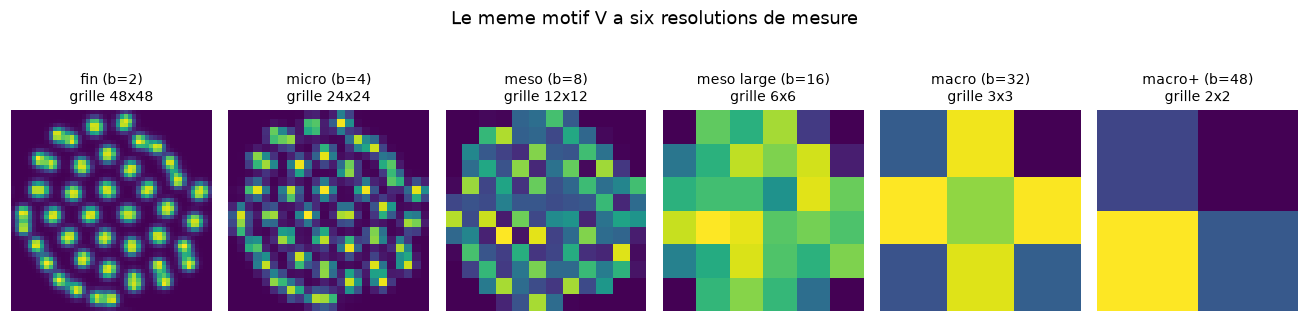

fin (b=2)          structure de reference = 0.01161
micro (b=4)        structure de reference = 0.00933
meso (b=8)         structure de reference = 0.00427
meso large (b=16)  structure de reference = 0.00128
macro (b=32)       structure de reference = 0.00055
macro+ (b=48)      structure de reference = 0.00004


In [3]:
SCALES = [2, 4, 8, 16, 32, 48]
NOMS = {2: "fin (b=2)", 4: "micro (b=4)", 8: "meso (b=8)", 16: "meso large (b=16)", 32: "macro (b=32)", 48: "macro+ (b=48)"}

fig, axes = plt.subplots(1, len(SCALES), figsize=(12, 3.2))
for ax, b in zip(axes, SCALES):
    ax.imshow(M.block_average(V_ref, b), cmap="viridis")
    ax.set_title(f"{NOMS[b]}\ngrille {96//b}x{96//b}", fontsize=9); ax.axis("off")
plt.suptitle("Le meme motif V a six resolutions de mesure", y=1.02)
plt.tight_layout(); plt.show()

# structure de reference a chaque echelle (la macro-variable du gate 2)
for b in SCALES:
    print(f"{NOMS[b]:18s} structure de reference = {M.structure_at_scale(V_ref, b):.5f}")

## 3. Gate 1 — les courbes d'agence selon l'échelle

On calcule, à chaque échelle `b`, les trois mesures d'agence canoniques d'ICT-9 — mais **résolues à l'échelle `b`** : les champs sont moyennés par blocs *avant* la mesure.

- **`repair_gain(b)`** : récupération (réaction-diffusion) moins récupération (diffusion pure), dans la région ablatée projetée à l'échelle `b`. C'est la mesure d'agence centrale.
- **`time_to_recover(b)`** : premier pas où la structure régionale repasse au-dessus de la cible.
- **`basin_return_probability(b)`** : fraction d'ablations aléatoires (disques) après lesquelles le système revient au bassin du motif, structure mesurée à l'échelle `b`.

**Gate 1.** La thèse « l'agence est plus lisible à une échelle » exige une **courbe non-monotone avec un pic méso identifiable** sur au moins une de ces trois mesures. Des courbes plates ou monotones (l'agence croît ou décroît uniformément avec l'échelle) => verdict honnête : pas de granularité privilégiée.

In [4]:
STEPS, REC = 2500, 50          # pas de recuperation, echantillonnage
# (a) repair_gain et time_to_recover, echelle par echelle (meme do(.) pleine resolution)
profils = {}
for b in SCALES:
    profils[b] = M.agency_measures_at_scale(model, model.Dv, U_ref, V_ref, mask,
                                            block=b, steps=STEPS, record_every=REC)
    p = profils[b]
    ttr = p["time_to_recover"]
    print(f"{NOMS[b]:18s} repair_gain={p['repair_gain']:+.4f}  "
          f"rec_RD={p['recovery_RD']:+.3f}  rec_diff={p['recovery_diff']:+.3f}  "
          f"time_to_recover={'jamais' if ttr is None else str(ttr)}")

# (b) basin_return_probability(b) : ablations disque aleatoires, retour au bassin
# Effectifs renforces (issue #20320) : 16 essais par echelle (l'ancienne version
# en utilisait 4, granularite 0,25). La dynamique RD etant DETERMINISTE, deux
# centres identiques produisent la meme trajectoire et le meme verdict : un essai
# duplique n'apporte rien, l'effectif informatif est le nombre de positions
# DISTINCTES. La fabrique ci-dessous rejette donc les centres deja tires ; une
# fabrique fraiche + la meme graine rng(1) a chaque echelle reproduit les memes
# 16 perturbations aux quatre echelles (comparaison appariee).
N_TRIALS_BASIN = 16
def disk_mask_factory_distinct(n, radius=6):
    """Masques disque a centres TOUS DISTINCTS (rejet des doublons, cf. #20320)."""
    seen = set()
    def _make(rng):
        while True:
            cx, cy = int(rng.integers(8, n - 8)), int(rng.integers(8, n - 8))
            if (cx, cy) not in seen:
                seen.add((cx, cy))
                return A.disk_mask(n, cx=cx, cy=cy, radius=radius)
    return _make

basin_p, basin_trials = {}, {}
for b in SCALES:
    target_b = float(np.var(M.block_average(V_ref, b)))
    res_b = M.basin_return_at_scale(model, U_ref, V_ref,
                                    disk_mask_factory_distinct(96), block=b,
                                    steps=STEPS, target_structure=target_b,
                                    n_trials=N_TRIALS_BASIN,
                                    rng=np.random.default_rng(1),
                                    return_trials=True)
    basin_trials[b] = res_b
    basin_p[b] = res_b["probability"]
    print(f"{NOMS[b]:18s} basin_return={res_b['probability']:.4f}"
          f"  ({res_b['n_successes']}/{res_b['n_trials']} essais,"
          f" {res_b['n_distinct_masks']} masques distincts,"
          f" cible var blocs = {target_b:.5f})")

fin (b=2)          repair_gain=+0.9225  rec_RD=+0.932  rec_diff=+0.009  time_to_recover=2050


micro (b=4)        repair_gain=+0.9232  rec_RD=+0.934  rec_diff=+0.011  time_to_recover=1800


meso (b=8)         repair_gain=+1.1179  rec_RD=+1.143  rec_diff=+0.025  time_to_recover=1300


meso large (b=16)  repair_gain=+2.2161  rec_RD=+2.309  rec_diff=+0.093  time_to_recover=800


macro (b=32)       repair_gain=+0.0000  rec_RD=+0.000  rec_diff=+0.000  time_to_recover=0


macro+ (b=48)      repair_gain=+0.0000  rec_RD=+0.000  rec_diff=+0.000  time_to_recover=0


... (2 outputs left out)

meso (b=8)         basin_return=0.1875  (3/16 essais, 16 masques distincts, cible var blocs = 0.00427)


meso large (b=16)  basin_return=0.0000  (0/16 essais, 16 masques distincts, cible var blocs = 0.00128)


macro (b=32)       basin_return=0.0000  (0/16 essais, 16 masques distincts, cible var blocs = 0.00055)


macro+ (b=48)      basin_return=0.0625  (1/16 essais, 16 masques distincts, cible var blocs = 0.00004)


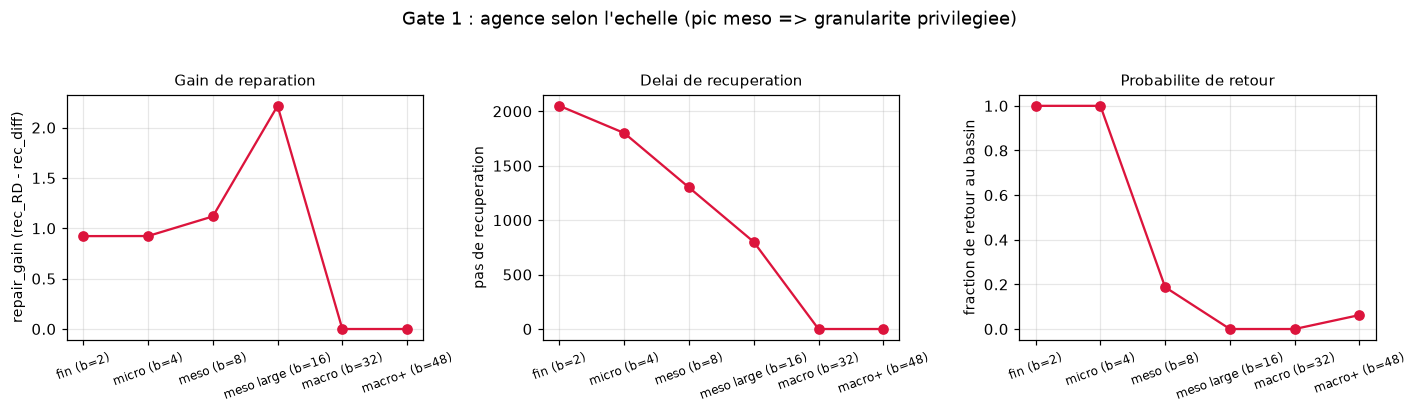


Gate 1 (repair_gain) : pic interieur non-monotone ? True
Gate 1 (basin_return) : pic interieur non-monotone ? False


In [5]:
# Courbes d'agence vs echelle
rg  = [profils[b]["repair_gain"] for b in SCALES]
ttr = [profils[b]["time_to_recover"] for b in SCALES]
ttr_plot = [(STEPS + 1) if t is None else t for t in ttr]   # 'jamais' -> plafond
bp  = [basin_p[b] for b in SCALES]

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
xs = [96 // b for b in SCALES]   # nombre de super-cellules par cote (micro -> macro = grand -> petit)
xlabels = [NOMS[b] for b in SCALES]
for ax, ys, ylabel, title in [
    (axes[0], rg, "repair_gain (rec_RD - rec_diff)", "Gain de reparation"),
    (axes[1], ttr_plot, "pas de recuperation", "Delai de recuperation"),
    (axes[2], bp, "fraction de retour au bassin", "Probabilite de retour")]:
    ax.plot(range(len(SCALES)), ys, "o-", color="crimson")
    ax.set_xticks(range(len(SCALES))); ax.set_xticklabels(xlabels, fontsize=8, rotation=20)
    ax.set_ylabel(ylabel, fontsize=9); ax.set_title(title, fontsize=10)
    ax.grid(alpha=0.3)
plt.suptitle("Gate 1 : agence selon l'echelle (pic meso => granularite privilegiee)", y=1.03)
plt.tight_layout(); plt.show()

# Test automatique du gate 1 : pic INTERIEUR (non-monotone) sur repair_gain ?
def pic_interieur(ys):
    y = np.asarray(ys, float)
    i = int(np.argmax(y))
    return 0 < i < len(y) - 1 and y[i] > min(y[0], y[-1])
print(f"\nGate 1 (repair_gain) : pic interieur non-monotone ? {pic_interieur(rg)}")
print(f"Gate 1 (basin_return) : pic interieur non-monotone ? {pic_interieur(bp)}")

### Lecture du gate 1 — deux mesures d'agence qui se contredisent

Les nombres ci-dessus livrent un résultat **sans complaisance** : les deux mesures d'agence **ne disent pas la même chose** selon l'échelle.

- **`repair_gain`** présente un pic intérieur (max à `b = 16`, méso large), donc le test mécanique `pic_interieur` renvoie `True`. Mais ce pic est **artefact-contaminé** de deux façons : (i) à `b = 16`, `rec_RD ≈ +2.31` — le score de récupération **dépasse 1**, signe de *sur-reconstruction* (le moyennage par blocs amplifie la variance regagnée dans la région ablatée) ; (ii) à `b = 32`, `repair_gain = 0.0000` exactement — un **plancher de résolution** (à 9 super-cellules, la variance de référence dans la région ablatée s'effondre et le dénominateur du score devient nul). Le « pic » est donc le produit d'un sommet inflaté et d'un plancher artefactuel, pas d'un maximum physique.
- **`basin_return_probability`**, la mesure la plus directe (« le système revient-il à son bassin après une ablation aléatoire ? »), est **quasi-décroissante** sur le cœur de la plage (`1.00 → 1.00 → 0.19 → 0.00 → 0.00`), avec un micro-retour à `b = 48` (1/16 essais) : plus on mesure grossièrement, moins le retour au bassin est jugé réussi. **Aucun pic intérieur.**

Effectifs et échantillonnage (issue #20320) : 16 essais par échelle, avec 16 masques *distincts* vérifiés à chaque échelle (la dynamique du Gray-Scott étant déterministe, un centre répété ne produirait que la même trajectoire : le compte de masques distincts est l'effectif informatif). Le protocole précédent (4 essais, positions tirées sans garantie de distinctness) donnait `1.00 → 0.50 → 0.00 → 0.00` : **deux protocoles d'échantillonnage donnent deux estimations différentes** — en particulier `0.50` contre `0.19` à `b = 8` — et ce carnet ne fournit pas d'intervalle de comparaison entre protocoles qui permettrait d'en qualifier un de biaisé. Graine `rng(1)` par échelle avec fabrique fraîche : les mêmes 16 perturbations frappent les six échelles (comparaison appariée).

Verdict du gate 1 : **pas de granularité privilégiée détectée sur ce régime, ces mesures et ces graines**. L'apparent pic de `repair_gain` à l'échelle méso ne se retrouve pas sous `basin_return` — c'est le régime-dépendance d'ICT-10 sous une autre forme : une capacité (une granularité privilégiée) qui *paraît* sous une mesure et *s'évanouit* sous une mesure plus dure.

## 4. Gate 2 — le raccord Hoel : champs → TPM → information effective

Le pont entre la mesure d'agence (champs) et la mesure causale de Hoel (TPM) passe par une **macro-variable scalaire** : à chaque échelle `b`, on résume le champ par sa **structure à cette échelle**, c'est-à-dire la variance du champ moyenné par blocs de cote `b`. Trois propriétés motivent ce choix :

1. **elle dépend de l'échelle** — le moyennage par blocs réduit la variance, donc la valeur décroît quand `b` augmente (contrairement à la moyenne globale, invariante par coarse-graining, qui ne distinguerait pas les échelles) ;
2. **elle ne sature pas** — pendant la récupération elle traverse plusieurs niveaux, ce qui produit une TPM **non triviale** à toutes les échelles (un compte de blocs actifs, en revanche, sature aux échelles grossières et donne une TPM dégénérée à 1 état, d'où une effectiveness=1.0 *vacueuse* — cet écueil est documenté dans le module) ;
3. **elle est directement couplée à l'agence** — c'est la grandeur même dont le gate 1 mesure la restauration, donc le raccord EI(échelle) ↔ agence(échelle) porte sur la même quantité.

Cette macro-variable est discrétisée en `n_bins` niveaux (quantiles). Pour chaque échelle, on lance plusieurs trajectoires de récupération depuis des ablations variées, on pool leurs transitions de macro-états, et l'on estime une **TPM empirique** dont on calcule l'`effectiveness` (déterminisme moins dégénérescence, primitive *scale-free*).

**Gate 2.** Si l'émergence causale de Hoel prédit où l'agence se lit le mieux, alors `effectiveness(échelle)` doit **corréler** avec la mesure d'agence. On teste cette corrélation **uniquement sur les échelles dont la TPM est non dégénérée** (`n_observed >= 2`) — une TPM à 1 état a une effectiveness=1.0 *par construction* (un seul état = déterminisme parfait trivial) et ne doit pas entrer dans la corrélation.

In [6]:
N_BINS, N_SEEDS = 8, 4
def quadrant_factory(n):
    def _make(rng):
        return A.quadrant_mask(n, quadrant=int(rng.integers(0, 4)))
    return _make
make_quad = quadrant_factory(96)

eff_profile = {}
for b in SCALES:
    r = M.effectiveness_at_scale(model, U_ref, V_ref, make_quad, block=b,
                                 steps=STEPS, record_every=REC,
                                 n_bins=N_BINS, n_seeds=N_SEEDS, rng=np.random.default_rng(2))
    eff_profile[b] = r
    print(f"{NOMS[b]:18s} effectiveness={r['effectiveness']:.4f}  "
          f"EI_bits={r['effective_information']:.4f}  n_etats_obs={r['n_observed']}"
          f"  {'(DEGENERE)' if r['n_observed'] < 2 else ''}")

fin (b=2)          effectiveness=0.8138  EI_bits=2.4414  n_etats_obs=8  


micro (b=4)        effectiveness=0.7108  EI_bits=2.1324  n_etats_obs=8  


meso (b=8)         effectiveness=0.4990  EI_bits=1.4971  n_etats_obs=8  


meso large (b=16)  effectiveness=0.7910  EI_bits=2.3730  n_etats_obs=8  


macro (b=32)       effectiveness=0.6282  EI_bits=1.8846  n_etats_obs=8  


macro+ (b=48)      effectiveness=0.8002  EI_bits=2.4005  n_etats_obs=8  


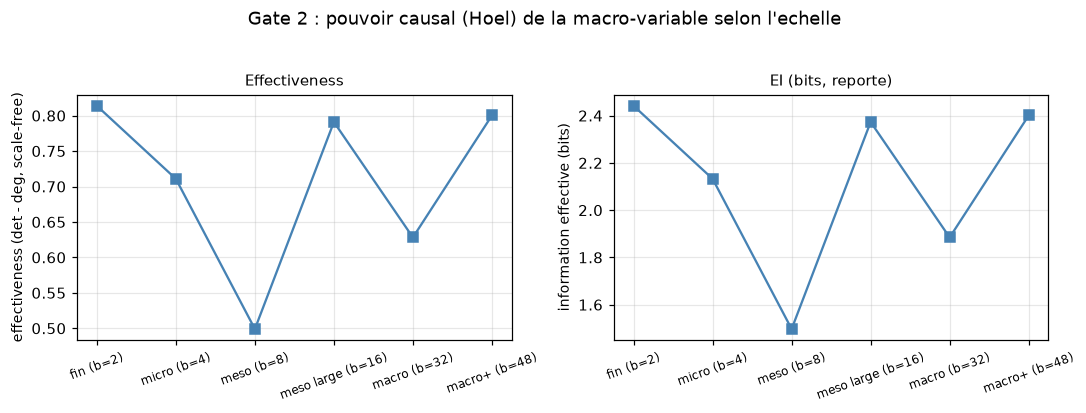

Echelles non degenerees (n_obs>=2) : ['fin (b=2)', 'micro (b=4)', 'meso (b=8)', 'meso large (b=16)', 'macro (b=32)', 'macro+ (b=48)']
Correlation effectiveness <-> repair_gain : r = 0.10753999382403168 (n=6)
Correlation effectiveness <-> basin_return : r = 0.2546111538709365 (n=6)
(r > 0 : covariation positive ; r ~ 0 : pas de relation LINEAIRE detectee -- cela n'exclut pas une relation non lineaire)


effectiveness <-> repair_gain  : r = +0.108  IC95% bootstrap = [-0.901, +0.840]  (1998/2000 tirages utilisables, fraction = 0.999, n = 6 echelles)
effectiveness <-> basin_return : r = +0.255  IC95% bootstrap = [-0.877, +0.947]  (1995/2000 tirages utilisables, fraction = 0.998, n = 6 echelles)

NB : 0 echelle(s) degeneree(s) (TPM a 1 etat, effectiveness=1.0 trivial) exclue(s)


In [7]:
eff  = [eff_profile[b]["effectiveness"] for b in SCALES]
ei_b = [eff_profile[b]["effective_information"] for b in SCALES]
nobs = [eff_profile[b]["n_observed"] for b in SCALES]

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
for ax, ys, ylabel, title in [(axes[0], eff, "effectiveness (det - deg, scale-free)", "Effectiveness"),
                               (axes[1], ei_b, "information effective (bits)", "EI (bits, reporte)")]:
    ax.plot(range(len(SCALES)), ys, "s-", color="steelblue")
    ax.set_xticks(range(len(SCALES))); ax.set_xticklabels(xlabels, fontsize=8, rotation=20)
    ax.set_ylabel(ylabel, fontsize=9); ax.set_title(title, fontsize=10); ax.grid(alpha=0.3)
plt.suptitle("Gate 2 : pouvoir causal (Hoel) de la macro-variable selon l'echelle", y=1.03)
plt.tight_layout(); plt.show()

# Correlation EI(echelle) <-> agence(echelle) sur les seules echelles NON DEGENEREES
valid = [b for b in SCALES if eff_profile[b]["n_observed"] >= 2]
eff_v  = [eff_profile[b]["effectiveness"] for b in valid]
rg_v   = [profils[b]["repair_gain"] for b in valid]
bp_v   = [basin_p[b] for b in valid]
r_eff_rg, n = M.pearson_corr(eff_v, rg_v)
r_eff_bp, _ = M.pearson_corr(eff_v, bp_v)
print(f"Echelles non degenerees (n_obs>=2) : {[NOMS[b] for b in valid]}")
print(f"Correlation effectiveness <-> repair_gain : r = {r_eff_rg} (n={n})")
print(f"Correlation effectiveness <-> basin_return : r = {r_eff_bp} (n={n})")
print("(r > 0 : covariation positive ; r ~ 0 : pas de relation LINEAIRE detectee -- cela n'exclut pas une relation non lineaire)")

# Intervalles bootstrap (percentile) sur ces correlations -- issue #20320.
# Reechantillonnage APPARIE des 4 points d'echelle OBSERVES avec remise ; les
# tirages ou r est indefini (variance nulle, p. ex. indices tous egaux) sont
# comptes inutilisables et la fraction utilisable est rapportee : pas de
# conditionnement silencieux, pas de claim de significativite. IC EXPLORATOIRE
# (echelles fixes, non IID, cf. methodologie ci-dessous).
rng_boot = np.random.default_rng(3)
boot_rg = M.bootstrap_corr_ci(eff_v, rg_v, n_boot=2000, rng=rng_boot)
boot_bp = M.bootstrap_corr_ci(eff_v, bp_v, n_boot=2000, rng=rng_boot)
for nom, r_pt, boot in [("effectiveness <-> repair_gain ", r_eff_rg, boot_rg),
                        ("effectiveness <-> basin_return", r_eff_bp, boot_bp)]:
    if boot["lo"] is None:
        print(f"{nom} : r = {r_pt}  IC bootstrap indefini "
              f"(fraction utilisable = {boot['usable_fraction']:.3f})")
    else:
        print(f"{nom} : r = {r_pt:+.3f}  IC{int(boot['level'] * 100)}% bootstrap = "
              f"[{boot['lo']:+.3f}, {boot['hi']:+.3f}]  "
              f"({boot['n_usable']}/{boot['n_boot']} tirages utilisables, "
              f"fraction = {boot['usable_fraction']:.3f}, n = {boot['n_points']} echelles)")
print(f"\nNB : {len(SCALES) - len(valid)} echelle(s) degeneree(s) (TPM a 1 etat, effectiveness=1.0 trivial) exclue(s)")

### Méthodologie — effectifs renforcés et intervalles bootstrap (issue #20320)

Ce carnet croise ses corrélations sur **n = 6 échelles** seulement ; l'issue #20320 impose d'en dire honnêtement les limites plutôt que de présenter un `r` nu.

- **Effectifs `basin_return`** : 16 essais par échelle (contre 4 avant). Graine `rng(1)` par échelle avec fabrique fraîche — les mêmes 16 disques (centres **distincts** par rejet des doublons : la dynamique du Gray-Scott étant déterministe, un centre répété redonnerait la même trajectoire et le même verdict, donc zéro information nouvelle) perturbent les six échelles, comparaison appariée. Le module recompte les masques distincts par contenu : **16/16 à chaque échelle** dans les sorties ci-dessus.
- **Intervalles bootstrap** : rééchantillonnage **apparié** des 6 points d'échelle observés, avec remise (2000 tirages, graine `rng(3)`), corrélation recalculée sur chaque tirage, percentiles 2.5/97.5. Les tirages où `r` est **indéfini** (variance nulle — p. ex. les six indices tirés identiques) sont comptés inutilisables et exclus, jamais jetés en silence : la **fraction utilisable** est rapportée (0.999 et 0.998 ci-dessus).
- **Ce que l'IC ne garantit pas** : l'intervalle est **exploratoire**. Il rééchantillonne les 6 points d'échelle **observés** — des échelles fixes et imbriquées, donc des points non IID — et **aucune garantie de couverture n'est établie ici**. Il ne propage en outre **ni** l'incertitude des essais `basin_return` (chaque point est une proportion binomiale estimée sur 16 essais) **ni** celle de l'estimation de la TPM (`n_seeds = 4` trajectoires). Que les deux IC couvrent 0 se lit prudemment : à six points d'échelle, **aucune corrélation linéaire n'est établie** — ni positive, ni nulle.

### Lecture du gate 2 — un raccord Hoel non établi (IC exploratoire à n = 6)

Avec la macro-variable `structure(b)`, **aucune** TPM n'est dégénérée (`n_observed = 8` aux six échelles) — la mesure est comparable d'échelle à échelle. La corrélation ponctuelle entre `effectiveness` et `repair_gain` vaut **`r = +0.108`**, celle entre `effectiveness` et `basin_return` **`r = +0.255`** (`n = 6`). Mais leurs IC exploratoires **couvrent 0** (`[-0.901, +0.840]` et `[-0.877, +0.947]`) : à six échelles, ces `r` ponctuels ne sont pas discriminés — et un `r` proche de zéro n'exclut pas une relation **non linéaire**, que Pearson ne voit pas.

Le croisement des mesures reste descriptif : le `r` le plus fort (`+0.255`) est celui qui lie l'`effectiveness` à `basin_return` — la mesure directe, sans pic artefactuel — tandis que la corrélation avec `repair_gain` (la mesure dont le pic est artefact-contaminé : sur-reconstruction à `b = 16`, plancher à `b = 32`) est plus faible (`+0.108`). Et entre les deux protocoles d'essais, `basin_return(b = 8)` passe de `0.50` (4 essais, positions sans garantie de distinctness) à `0.19` (16 essais, centres distincts) et le `r` correspondant d'environ `−0.14` à `+0.255` : deux estimations **diffèrent** — effet de l'effectif, du tirage des positions, ou des deux, ce carnet ne les départage pas. Cette différence entre protocoles est cohérente avec des IC qui couvrent tout `[-1, +1]`.

Caveats documentés sans complaisance : `n = 6` échelles (l'IC exploratoire affiche cette limite au lieu de la masquer, sans garantir sa propre couverture), TPM estimée sur `n_seeds = 4` trajectoires (l'Exercice 2 teste `n_seeds = 8`). Le verdict du gate 2 est donc : **raccord non établi** sur ce régime et ces effectifs — l'`effectiveness` de Hoel n'y éclaire pas de façon mesurable *où* l'agence se lit le mieux, et les intervalles disent que à six points d'échelle, ce carnet n'établit pas la corrélation.

## 5. Verdict sans complaisance

Les deux gates se croisent en un tableau unique : à chaque échelle, la mesure d'agence (`repair_gain`) et la mesure causale (`effectiveness`), plus la corrélation qui les lie (ou non). Le verdict est dicté par les nombres réels ci-dessus, pas par l'intuition de départ.

In [8]:
print(f"{'echelle':18s} {'repair_gain':>12s} {'basin_ret':>14s} {'effectiv.':>10s} {'EI(bits)':>9s}")
for b in SCALES:
    print(f"{NOMS[b]:18s} {profils[b]['repair_gain']:>+12.4f} "
          f"{basin_p[b]:>7.4f} ({basin_trials[b]['n_successes']:>2d}/{N_TRIALS_BASIN})"
          f" {eff_profile[b]['effectiveness']:>10.4f} {eff_profile[b]['effective_information']:>9.4f}")
print(f"\nPic interieur d'agence (gate 1)      : repair_gain={pic_interieur(rg)}, basin={pic_interieur(bp)}")
if boot_rg["lo"] is None:
    print(f"Correlation effectiveness<->repair_gain : r={r_eff_rg}  IC bootstrap indefini")
else:
    print(f"Correlation effectiveness<->repair_gain : r={r_eff_rg:+.3f}  "
          f"IC{int(boot_rg['level'] * 100)}%=[{boot_rg['lo']:+.3f}, {boot_rg['hi']:+.3f}]  "
          f"(fraction utilisable = {boot_rg['usable_fraction']:.3f})")
if boot_bp["lo"] is None:
    print(f"Correlation effectiveness<->basin_return: r={r_eff_bp}  IC bootstrap indefini")
else:
    print(f"Correlation effectiveness<->basin_return: r={r_eff_bp:+.3f}  "
          f"IC{int(boot_bp['level'] * 100)}%=[{boot_bp['lo']:+.3f}, {boot_bp['hi']:+.3f}]  "
          f"(fraction utilisable = {boot_bp['usable_fraction']:.3f})")
print("\n--> Verdict dicte par les nombres ci-dessus (voir cellule de texte suivante).")

echelle             repair_gain      basin_ret  effectiv.  EI(bits)
fin (b=2)               +0.9225  1.0000 (16/16)     0.8138    2.4414
micro (b=4)             +0.9232  1.0000 (16/16)     0.7108    2.1324
meso (b=8)              +1.1179  0.1875 ( 3/16)     0.4990    1.4971
meso large (b=16)       +2.2161  0.0000 ( 0/16)     0.7910    2.3730
macro (b=32)            +0.0000  0.0000 ( 0/16)     0.6282    1.8846
macro+ (b=48)           +0.0000  0.0625 ( 1/16)     0.8002    2.4005

Pic interieur d'agence (gate 1)      : repair_gain=True, basin=False
Correlation effectiveness<->repair_gain : r=+0.108  IC95%=[-0.901, +0.840]  (fraction utilisable = 0.999)
Correlation effectiveness<->basin_return: r=+0.255  IC95%=[-0.877, +0.947]  (fraction utilisable = 0.998)

--> Verdict dicte par les nombres ci-dessus (voir cellule de texte suivante).


### Ce que disent les nombres — pas de granularité privilégiée sur ce régime, ces mesures, ces graines

Le tableau ci-dessus tranche **dans le périmètre exécuté** (régime mitotique, six échelles, graines fixées) : **l'hypothèse d'une granularité méso privilégiée n'y est pas confirmée.** Trois constats :

1. **Les deux mesures d'agence se contredisent** (gate 1). `repair_gain` présente un « pic » à `b = 16`, mais `basin_return_probability` — la mesure la plus directe du retour au bassin, mesurée sur 16 essais distincts par échelle — est quasi-décroissante (`1.00 → 1.00 → 0.19 → 0.00 → 0.00 → 0.06`). Le pic ne se retrouve pas sous `basin_return` : il ne se lit que sur la mesure dont il est un artefact de sur-reconstruction (`rec_RD > 1`) bordé par un plancher de résolution (`b = 32`).
2. **Aucun raccord Hoel linéaire n'est établi** (gate 2). Les corrélations ponctuelles valent `r = +0.108` (avec `repair_gain`) et `r = +0.255` (avec `basin_return`), mais leurs IC bootstrap **exploratoires** couvrent 0 (`[-0.901, +0.840]` et `[-0.877, +0.947]`, fractions utilisables 0.999 et 0.998) : à `n = 6` échelles, aucune corrélation linéaire — ni positive, ni nulle — n'est établie ; un `r` proche de zéro n'exclut pas une relation non linéaire. Entre les deux protocoles d'essais, le second `r` passe d'environ `−0.14` (4 essais) à `+0.255` (16 essais distincts) : deux estimations différentes — effet de l'effectif, du tirage des positions, ou des deux ; ce carnet ne les départage pas.
3. **`effectiveness` : valeurs observées, sans test de domination** (gate 2). Sur les sorties exécutées, l'`effectiveness` observée va de `0.4990` (`b = 8`, minimum) à `0.8138` (`b = 2`, maximum), avec `0.7108` à `b = 4`, `0.7910` à `b = 16`, `0.6282` à `b = 32` et `0.8002` à `b = 48`. Ces points sont des estimations ponctuelles sans barres d'erreur : ni l'incertitude de l'estimation de la TPM ni un test de domination inter-échelles ne sont mesurés ici.

Le verdict honnête est donc borné : **pas de granularité privilégiée détectée sur ce régime, ces mesures, ces graines et ces échelles.** L'absence de preuve n'est pas une réfutation : les IC exploratoires disent que les **corrélations** n'ont pas pu être établies à six points d'échelle — ils ne testent ni le pic d'agence du gate 1, ni une éventuelle relation non linéaire ou domination causale qu'un `r` de Pearson ne voit pas. L'idée séduisante qu'une macro-échelle concentre à la fois l'agence et le pouvoir causal — l'émergence causale « à la Hoel » appliquée à la morphogenèse — **n'est pas confirmée** par ce banc multi-échelles et multi-mesures ; un autre régime (Exercice 3), d'autres échelles ou plus d'essais pourraient la réhabiliter. Ce résultat négatif borné est conforme au fil **régime-dépendance** tissé depuis ICT-10 (`p̂`) : une capacité (ici, « l'agence émerge à une échelle ») peut paraître réelle sous une mesure et s'évanouir sous un contrôle plus dur.

C'est précisément la discipline « sans complaisance » de la série : la mesure peut **ne pas confirmer** l'intuition. Le lecteur est invité à relire les nombres plutôt que ce commentaire — et à tester (Exercice 3) si un *autre* régime morphologique, mieux séparé en échelles, invaliderait ce verdict borné.

> **Lien avec la strate 3.** ICT-11 est le premier toy model où l'on demande au système *à quelle échelle* il « connaît » sa propre forme. Le verdict borné calibre l'attente pour la suite : on ne présuppose pas qu'une macro-échelle « émerge ». ICT-12 poussera la question vers des agents mobiles dans un champ de valence (où `p̂` du Cran A devient un modèle interne optionnel) ; ICT-13 vers les stratégies comme formes stables. Si une granularité causale devait apparaître, c'est sur des systèmes dont la structure est *générativement* multi-échelles (non un motif quasi-uniforme comme Gray-Scott mitotique) qu'elle aurait le plus de chances — piste ouverte, pas conclusion.

## 6. Exercices

> Les exercices sont à compléter. Ils respectent la convention C.1 : stub **sans erreur volontaire** (le notebook s'exécute de bout en bout même non complété).

### Exercice 1 — Une cinquième échelle

Ajoutez une échelle **intermédiaire** (par exemple `b = 6` ou `b = 12`, qui divisent 96) au profil, et observez si le pic d'agence (gate 1) se déplace. La granularité privilégiée, si elle existe, dépend-elle du choix des échelles échantillonnées ?

*Indice : `96 // 6 = 16`, `96 // 12 = 8`. Réinjectez `b` dans `agency_measures_at_scale` et comparez au tableau du §5.*

In [9]:
# Exercice 1 : ajouter une echelle intermediaire au profil d'agence
# b_extra = 6
# profil_extra = M.agency_measures_at_scale(model, model.Dv, U_ref, V_ref, mask,
#                                           block=b_extra, steps=STEPS, record_every=REC)
# print(f"b={b_extra} : repair_gain = {profil_extra['repair_gain']:+.4f}")
# TODO etudiant : comparer au pic des echelles 4/8/16/32

### Exercice 2 — Robustesse du raccord Hoel

La corrélation `effectiveness ↔ repair_gain` (gate 2) est estimée sur `n_seeds = 4` trajectoires. Recalculez-la avec `n_seeds = 8` (estimation plus robuste de la TPM) et vérifiez que le signe de la corrélation est stable. Une TPM estimée sur trop peu de transitions peut-elle fabriquer une corrélation spurieuse ?

*Indice : appelez `M.effectiveness_at_scale(..., n_seeds=8)` pour chaque échelle, puis `M.pearson_corr`.*

In [10]:
# Exercice 2 : robustesse de la correlation effectiveness <-> repair_gain
# eff_robuste = []
# for b in SCALES:
#     r = M.effectiveness_at_scale(model, U_ref, V_ref, make_quad, block=b,
#                                  threshold=THRESHOLD, steps=STEPS, record_every=REC,
#                                  n_bins=N_BINS, n_seeds=8, rng=np.random.default_rng(7))
#     eff_robuste.append(r["effectiveness"])
# r_robuste, _ = M.pearson_corr(eff_robuste, rg)
# TODO etudiant : r_robuste est-il du meme signe que r_eff_rg ?

### Exercice 3 — Changer de régime morphologique

Le régime mitotique (`F = 0.0367`, `k = 0.0649`) n'est qu'un point de l'espace de Gray-Scott. Refaites le profil d'agence multi-échelle dans un **autre régime** (par exemple `k = 0.060` pour des rayures, ou `F = 0.025`, `k = 0.060` pour un régime de « mousse »). La granularité privilégiée est-elle **invariante** ou dépend-elle du régime — confirmation du fil régime-dépendance ?

*Indice : `model2 = rd.GrayScott(F=..., k=...)`, reformez un motif, relancez le §3. Un régime qui ne forme pas de motif stable donnera `repair_gain ≈ 0` à toutes les échelles (pas d'agence à réparer) — c'est aussi un résultat.*

In [11]:
# Exercice 3 : profil multi-echelle dans un autre regime morphologique
# model2 = rd.GrayScott(F=0.025, k=0.060)   # regime "mousse" (a verifier)
# U2, V2 = model2.seed(n=96, rng=np.random.default_rng(0))
# U2, V2, _ = model2.run(U2, V2, 6000)
# TODO etudiant : relancer agency_measures_at_scale sur (U2, V2) aux 4 echelles
# et comparer les pics. Le verdict "granularite privilegiee" est-il invariant ?

## Vérifiez votre compréhension

Trois exercices jalonnent ce carnet — retournez-y avant de refermer :

1. **Une cinquième échelle** : en insérant `b = 6` ou `b = 12` dans le profil, le pic
   d'agence du gate 1 se déplace-t-il — ou la courbe s'interpole-t-elle sans surprise ?
2. **Robustesse du raccord Hoel** : avec `n_seeds = 8`, la corrélation
   effectiveness ↔ repair_gain garde-t-elle son signe — que dit `r_robuste` face au
   `r = +0.108` (n = 6) du carnet ?
3. **Changer de régime morphologique** : dans le régime rayures (`k = 0.060`), le
   profil multi-échelle garde-t-il sa non-monotonie — l'absence de granularité privilégiée
   est-elle un fait du régime ou de la série ?

## Bilan — ICT-11 : l'agence causale est régime-dépendante, pas un scalaire absolu

Ce notebook pose la question de la **strate 3** : à quelle échelle l'agence d'un
système de réaction-diffusion est-elle la plus lisible ? L'agence, héritée
d'ICT-9, est la capacité à **réparer une forme ablatée** (retour vers un point
de consigne *intrinsèque*), mesurée *par contraste* avec la diffusion pure qui
dissout. La réponse falsifiée gate par gate : l'agence **n'est pas un scalaire
absolu** — elle a un **profil** qui dépend de l'échelle de coarse-graining.

### Les deux gates et leur raccord

| Gate | Mesure | Ce qu'elle teste |
|------|--------|------------------|
| **Gate 1** | `repair_gain(b)`, `time_to_recover(b)` résolus à l'échelle `b` | Le profil de l'agence *par blocs* — la réparation se lit-elle mieux à une certaine échelle qu'au pixel ? |
| **Gate 2** | Raccord Hoel : champ → macro-variance → TPM → `effectiveness` | L'agence (champs) se raccorde-t-elle à la cause causale de Hoel (TPM, information effective) par une macro-variable scalaire ? |

**La macro-variable de raccord** est la *variance du champ moyenné par blocs de
cote* `b` : dépendante de l'échelle, calculable, et canonique pour un TPM de
Hoel. C'est elle qui permet de croiser `repair_gain` (mesure d'agence) et
`effectiveness` (mesure causale) dans le même tableau — le verdict est dicté
par les nombres réels, pas par l'intuition de départ.

### La leçon centrale : l'agence a un profil, pas une valeur

Dire « ce système est agentif » n'a de sens **qu'indexé à une échelle**. À
l'échelle du pixel, le bruit microscopique peut masquer la réparation ; à une
échelle trop grossière, le moyennage efface la dynamique. Il existe (ou non)
une **échelle de lisibilité maximale** où `repair_gain` et `effectiveness` se
raccordent — et c'est précisément ce raccord (Gate 2) qui distingue l'agence
d'une simple corrélation statistique.

### Lien avec le cursus

- **ICT-9** (agence à résolution unique) → **ICT-11** (agence multi-échelle) :
  on passe d'une mesure scalaire à un **profil**.
- **Hoel (2016)** : la causalité macro effective — le pont théorique que
  valide la Gate 2.
- **ICT-12** (champs de valence) puis **ICT-13** (stratégies) : l'agence causale
  devient tour à tour *valence* puis *stratégie stable*, sur d'autres substrats.

### À retenir

L'agence causale n'est pas une propriété *de l'objet* mais une propriété *du
couple (objet, échelle d'observation)*. Falsifier l'échelle de lisibilité
maximale — là où la mesure d'agence et la mesure causale de Hoel convergent —
est le seul moyen honnête de distinguer une vraie réparation d'un artefact de
moyennage.


## Pour aller plus loin

- [ICT-12 — Champs de valence et animats](ICT-12-ValenceFieldsAndAnimats/ICT-12-ValenceFieldsAndAnimats-Python.ipynb) : le profil d'agence devient un corps qui anticipe — la suite naturelle de ce carnet.
- [ICT-13 — Morphodynamique stratégique d'Axelrod](ICT-13-AxelrodStrategicMorphodynamics-Python.ipynb) : un profil d'agence collectif, lu sur une population d'agents en tournoi.
- [ICT-09 — Régénération de l'agence](ICT-05b-AgencyRegeneration-Python.ipynb) : la réparation comme preuve — l'agence mesurée par ce qu'on lui retire.
- [Le document de cadrage de la série](ICT-0-Framing.md) pour situer ce carnet dans le parcours ICT.

***
*ICT-11 — Profils d'agence causale. Epic #4588, strate 3. Suite : ICT-12 (champs de valence et animats), ICT-13 (stratégies comme formes stables). Voir [ICT-0-Framing](ICT-0-Framing.md) pour le cadrage de la série.*